# Independent disease CNN – DPD_Small_clean_v2 (shared protocol)

Main run = the dataset's own `train_independent.py --task disease`, **unchanged** (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny). This notebook only runs it, checks the output files, analyses the results for the report, and prepares the checksums and the team message. No data preparation is run (the dataset is prebuilt).

**Order:** 1 setup → 2 smoke test (optional) → 3 main run (~1.5 h on a T4) → 4 check outputs → 5 results → 6 analysis → 7 checksums and zip.

## 1. Setup

In [1]:
!pip -q install timm

**Colab only:** mount Drive and copy the dataset locally first (Drive is slow to read). Skip this cell on Kaggle.

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import os, subprocess, pandas as pd

V1 = "/content/drive/MyDrive/DPD_Small_clean"          # has all 11,443 images
V2 = "/content/drive/MyDrive/DPD_Small_clean_v2"       # has the CSVs/scripts, only 3,128 images
ROOT = "/content/DPD_Small_clean_v2"
os.makedirs(f"{ROOT}/images", exist_ok=True)

# code + CSVs from v2, then images from v1 first and v2 on top
subprocess.run(["rsync", "-a", "--exclude", "images", f"{V2}/", f"{ROOT}/"], check=True)
subprocess.run(["rsync", "-a", f"{V1}/images/", f"{ROOT}/images/"], check=True)
subprocess.run(["rsync", "-a", f"{V2}/images/", f"{ROOT}/images/"], check=True)
print("images:", len(os.listdir(f"{ROOT}/images")), "(expected 11443)")

total_missing = 0
for f in ["train", "val", "val_unseen", "test_seen", "test_unseen"]:
    d = pd.read_csv(f"{ROOT}/{f}.csv")
    miss = [p for p in d["path"] if not os.path.isfile(f"{ROOT}/{p}")]
    print(f"{f}: {len(d)} rows, {len(miss)} missing"); total_missing += len(miss)
print("TOTAL missing:", total_missing)

Mounted at /content/drive
images: 11443 (expected 11443)
train: 6995 rows, 0 missing
val: 773 rows, 0 missing
val_unseen: 227 rows, 0 missing
test_seen: 2000 rows, 0 missing
test_unseen: 1448 rows, 0 missing
TOTAL missing: 0


In [3]:
import glob, os, json, re, hashlib, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
OUT_ROOT, WORKERS = ("/kaggle/working", 4) if ON_KAGGLE else ("/content/drive/MyDrive/DPD_runs/v2", 2)
hits = (glob.glob("/content/DPD_Small_clean_v2/**/label_maps.json", recursive=True)
        or glob.glob("/kaggle/input/**/label_maps.json", recursive=True))
assert hits, "label_maps.json not found: add the DPD_Small_clean_v2 dataset (Kaggle) or copy it to /content (Colab)."
DATA = os.path.dirname(hits[0])
RUN = f"{OUT_ROOT}/disease_independent_v2"
MODELS = ["ResNet50", "EfficientNet-B0", "ConvNeXt-Tiny"]
SPLITS = ["val", "val_unseen", "seen", "unseen"]
os.makedirs(OUT_ROOT, exist_ok=True)
print("Dataset:", DATA); print("Output :", RUN); print("Workers:", WORKERS)
print(sorted(os.listdir(DATA)))

Dataset: /content/DPD_Small_clean_v2
Output : /content/drive/MyDrive/DPD_runs/v2/disease_independent_v2
Workers: 2
['README.md', 'V2_CHANGES.md', '__init__.py', 'dataset.py', 'images', 'label_maps.json', 'manifest.csv', 'metrics.py', 'stats.json', 'test_seen.csv', 'test_unseen.csv', 'train.csv', 'train_independent.py', 'val.csv', 'val_unseen.csv']


## 2. Smoke test (optional, about 2 minutes)
One backbone, one epoch, 3 batches. Confirms the script, the data and the GPU work before the long run.

In [4]:
import os, shutil, hashlib, pandas as pd
from concurrent.futures import ThreadPoolExecutor

V1  = "/content/drive/MyDrive/DPD_Small_clean/images"
V2  = "/content/drive/MyDrive/DPD_Small_clean_v2/images"
ROOT = "/content/DPD_Small_clean_v2"; LOC = f"{ROOT}/images"
os.makedirs(LOC, exist_ok=True)

def index(d):   # name -> full path (handles subfolders)
    return {f: os.path.join(dp, f) for dp, _, fs in os.walk(d) for f in fs}
i1, i2 = index(V1), index(V2)
print("v1 files:", len(i1), "| v2 files:", len(i2))

# 1) are the overlapping files identical?
common = sorted(set(i1) & set(i2))
diff_size = [f for f in common if os.path.getsize(i1[f]) != os.path.getsize(i2[f])]
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
diff_md5 = [f for f in common[:200] if md5(i1[f]) != md5(i2[f])]
print(f"overlap: {len(common)} | different size: {len(diff_size)} | different md5 (first 200): {len(diff_md5)}")
print("v2 files missing from v1:", len(set(i2) - set(i1)))

v1 files: 11443 | v2 files: 3128
overlap: 3128 | different size: 21 | different md5 (first 200): 0
v2 files missing from v1: 0


In [5]:
!python {DATA}/train_independent.py --task disease --out {OUT_ROOT}/smoke --models ResNet50 --epochs 1 --limit-batches 3

split sizes: {'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448} | device: cuda

===== ResNet50 (resnet50.tv2_in1k) =====

model.safetensors: downloading bytes:   0% 0.00/102M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  90% 92.1M/102M [00:01<00:00, 147MB/s, 6.00MB/s  ] 
model.safetensors: downloading bytes: 100% 96.5M/96.5M [00:01<00:00, 56.1MB/s, 9.11MB/s  ]
model.safetensors: reconstructing file: 100% 102M/102M [00:01<00:00, 59.5MB/s, 9.84MB/s  ]
[ResNet50] ep 01 | train loss 5.0966 acc(aug) 5.73 | val 3.65 | val_unseen 1.04 | H 1.62 | 7s
{
 "best_epoch": 1,
 "seen": {
  "1": 3.125,
  "3": 8.33333358168602,
  "5": 10.41666641831398,
  "per_class_top1": 0.754727739276308
 },
 "unseen": {
  "1": 1.0416666977107525,
  "3": 3.125,
  "5": 6.25,
  "per_class_top1": 1.0416666977107525
 },
 "harmonic": {
  "1": 1.5625000349245963,
  "3": 4.5454545823995725,
  "5": 7.812499930150806,
  "per_class_top1": 0.875280768694917
 }
}
   Model  Val Top-1  

## 3. Main run (do not change the script)
The first lines of the log should show the split sizes **train 6995, val 773, val_unseen 227, test_seen 2000, test_unseen 1448**. `results.json` is rewritten after each backbone, so finished backbones survive a disconnect.

In [6]:
!python {DATA}/train_independent.py --task disease --out {RUN} --workers {WORKERS}

split sizes: {'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448} | device: cuda

===== ResNet50 (resnet50.tv2_in1k) =====
[ResNet50] ep 01 | train loss 4.6348 acc(aug) 17.07 | val 30.53 | val_unseen 0.00 | H 0.00 | 69s
[ResNet50] ep 02 | train loss 2.6940 acc(aug) 49.20 | val 63.39 | val_unseen 2.64 | H 5.07 | 69s
[ResNet50] ep 03 | train loss 1.8901 acc(aug) 68.68 | val 68.95 | val_unseen 5.73 | H 10.58 | 71s
[ResNet50] ep 04 | train loss 1.5694 acc(aug) 76.76 | val 75.16 | val_unseen 5.73 | H 10.64 | 71s
[ResNet50] ep 05 | train loss 1.3991 acc(aug) 82.37 | val 76.58 | val_unseen 14.98 | H 25.06 | 72s
[ResNet50] ep 06 | train loss 1.2747 acc(aug) 86.30 | val 75.94 | val_unseen 10.57 | H 18.56 | 70s
[ResNet50] ep 07 | train loss 1.1878 acc(aug) 89.78 | val 79.43 | val_unseen 8.37 | H 15.14 | 70s
[ResNet50] ep 08 | train loss 1.1289 acc(aug) 91.69 | val 77.10 | val_unseen 10.13 | H 17.91 | 67s
[ResNet50] ep 09 | train loss 1.0891 acc(aug) 93.12 | val 

## 4. Check that every required output exists

In [7]:
required = ["config.json", "results.json", "summary.csv", "all_models_accuracy.png", "harmonic_mean.png"]
for m in MODELS:
    required += [f"{m}_history.csv", f"{m}_curves.png", f"{m}_best.pt"]
    for s in SPLITS:
        required += [f"{m}_{s}_confusion_matrix.csv", f"{m}_{s}_confusion_matrix.png", f"{m}_predictions_{s}.csv"]
missing = [f for f in required if not os.path.isfile(f"{RUN}/{f}")]
print("Missing files:", missing if missing else "none")

cfg = json.load(open(f"{RUN}/config.json"))
print("dataset :", cfg.get("dataset"))
print("timm ids:", {k: v for k, v in cfg.items() if "timm" in k.lower()} or cfg.get("models", "see config.json"))
print("gpu     :", cfg.get("gpu") or cfg.get("device"))
print("summary rows:", len(pd.read_csv(f"{RUN}/summary.csv")), "(expected 3)")

Missing files: none
dataset : DPD_Small_clean_v2
timm ids: {'ResNet50': {'timm_id': 'resnet50.tv2_in1k', 'lr': 0.0003}, 'EfficientNet-B0': {'timm_id': 'efficientnet_b0.ra_in1k', 'lr': 0.0005}, 'ConvNeXt-Tiny': {'timm_id': 'convnext_tiny.fb_in1k', 'lr': 0.0001}}
gpu     : Tesla T4
summary rows: 3 (expected 3)


## 5. Results

In [8]:
res = json.load(open(f"{RUN}/results.json"))
rows = []
for m, r in res.items():
    rows.append({"Model": m, "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
                 "Train(clean) Top-1": r["train_clean_top1"],
                 "Val Top-1": r["val"]["1"], "ValUnseen Top-1": r["val_unseen"]["1"],
                 "Seen Top-1": r["seen"]["1"], "Seen Top-5": r["seen"]["5"],
                 "Seen(excl heldout) Top-1": r["seen_excl_heldout"]["1"],
                 "Unseen Top-1": r["unseen"]["1"], "Unseen Top-5": r["unseen"]["5"],
                 "H Top-1": r["harmonic"]["1"], "H Top-5": r["harmonic"]["5"]})
table = pd.DataFrame(rows).set_index("Model").round(2)
display(table)
table.to_csv(f"{RUN}/results_table_for_report.csv")
best = table["H Top-1"].idxmax(); print("Best backbone by H Top-1:", best)

,best_epoch,epochs_run,Train(clean) Top-1,Val Top-1,ValUnseen Top-1,Seen Top-1,Seen Top-5,Seen(excl heldout) Top-1,Unseen Top-1,Unseen Top-5,H Top-1,H Top-5
Model,,,,,,,,,,,,
ResNet50,15,25,98.66,82.41,15.42,65.05,83.70,66.91,8.63,27.97,15.24,41.93
EfficientNet-B0,15,25,99.36,80.60,14.10,64.85,83.75,66.70,8.91,26.66,15.67,40.44
ConvNeXt-Tiny,10,20,91.07,81.37,16.30,64.30,84.35,66.13,14.09,33.29,23.11,47.74


Best backbone by H Top-1: ConvNeXt-Tiny


### 5.1 Training curves: `val` vs `val_unseen`
If `val_unseen` stays near 0 while `val` climbs, the model is learning crop → disease instead of symptoms.

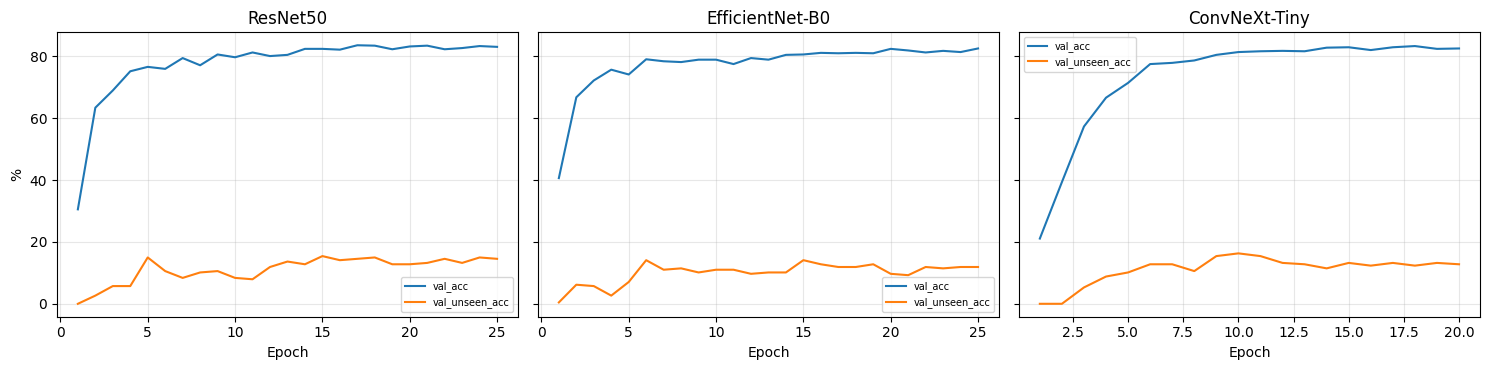

['epoch', 'train_loss', 'train_acc_aug', 'val_loss', 'val_acc', 'val_unseen_acc', 'val_H', 'secs']


In [9]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 3.8), sharey=True)
for ax, m in zip(np.atleast_1d(axes), MODELS):
    h = pd.read_csv(f"{RUN}/{m}_history.csv")
    cols = [c for c in h.columns if re.search(r"val|H_val", c, re.I) and re.search(r"top|acc|H_val", c, re.I) and "loss" not in c.lower()]
    for c in cols: ax.plot(h["epoch"], h[c], label=c)
    ax.set_title(m); ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=7)
np.atleast_1d(axes)[0].set_ylabel("%")
plt.tight_layout(); plt.savefig(f"{RUN}/val_vs_val_unseen_all.png", dpi=150); plt.show()
print(pd.read_csv(f"{RUN}/ConvNeXt-Tiny_history.csv").columns.tolist())

## 6. Analysis for the report: the crop shortcut
Uses `<Model>_predictions_unseen.csv` joined with `test_unseen.csv`. If a column name below does not match your files, the cell prints the actual columns; adjust the three names at the top of the cell.

In [10]:
# ---- column names (edit here if your files differ) ----
PRED_PATH, TRUE_COL, PRED1 = "path", None, "pred1"          # TRUE_COL=None -> auto-detect
CROP_COL, DIS_COL, NCROPS_COL = "crop_id", "disease_id", "disease_n_train_crops"

def find_csv(name):
    p = glob.glob(f"{DATA}/**/{name}", recursive=True)
    assert p, f"{name} not found under {DATA}"
    return p[0]

test_unseen = pd.read_csv(find_csv("test_unseen.csv"))
train       = pd.read_csv(find_csv("train.csv"))
print("test_unseen columns:", test_unseen.columns.tolist())
print("train columns      :", train.columns.tolist())
need = {CROP_COL, DIS_COL, NCROPS_COL} - set(test_unseen.columns)
assert not need, f"Missing columns in test_unseen.csv: {need} -> edit the names above"

def load_preds(model):
    p = pd.read_csv(f"{RUN}/{model}_predictions_unseen.csv")
    tc = TRUE_COL or next((c for c in ["true", "true_id", "y_true", "label", "target"] if c in p.columns), None)
    assert tc is not None, f"Cannot find the true-label column in {p.columns.tolist()}"
    return p.rename(columns={tc: "true_label", PRED1: "pred1"})

crops_per_disease_train = train.groupby(DIS_COL)[CROP_COL].apply(set).to_dict()
print("\nTraining crops per disease (describe):")
print(train.groupby(DIS_COL)[CROP_COL].nunique().describe().round(2))
print("Share of diseases seen on a single crop in train: "
      f"{(train.groupby(DIS_COL)[CROP_COL].nunique() == 1).mean()*100:.1f}%")

out = {}
for m in MODELS:
    p = load_preds(m)
    d = p.merge(test_unseen[[PRED_PATH, CROP_COL, DIS_COL, NCROPS_COL]], on=PRED_PATH, how="left")
    assert d[CROP_COL].notna().all(), "Some predictions did not join to test_unseen.csv (check the 'path' column)"
    d["correct"] = (d["pred1"].astype(str) == d["true_label"].astype(str))
    wrong = d[~d["correct"]].copy()
    wrong["pred_int"] = pd.to_numeric(wrong["pred1"], errors="coerce")
    wrong["pred_seen_on_true_crop"] = [
        (not np.isnan(pr)) and (cr in crops_per_disease_train.get(int(pr), set()))
        for pr, cr in zip(wrong["pred_int"], wrong[CROP_COL])]
    out[m] = dict(
        by_ncrops = d.groupby(NCROPS_COL)["correct"].agg(["mean", "count"]).rename(columns={"mean": "top1", "count": "n_images"}).assign(top1=lambda x: (x.top1*100).round(1)),
        by_disease = d.groupby(DIS_COL)["correct"].agg(["mean", "count"]).rename(columns={"mean": "top1", "count": "n_images"}).assign(top1=lambda x: (x.top1*100).round(1)),
        shortcut = wrong["pred_seen_on_true_crop"].mean() * 100 if len(wrong) else float("nan"))
    print(f"\n=== {m} ===")
    print(f"Wrong unseen predictions that are a disease seen on the TRUE crop in training: {out[m]['shortcut']:.1f}%")
    print("Unseen Top-1 by number of training crops of the true disease:")
    display(out[m]["by_ncrops"])
    out[m]["by_ncrops"].to_csv(f"{RUN}/{m}_unseen_by_n_train_crops.csv")
    out[m]["by_disease"].to_csv(f"{RUN}/{m}_unseen_by_disease.csv")

test_unseen columns: ['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled', 'heldout_pair', 'disease_n_train_crops', 'source_n_train_crops', 'source_in_train', 'comp_n_train_sources']
train columns      : ['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled', 'heldout_pair', 'disease_n_train_crops', 'source_n_train_crops', 'source_in_train', 'comp_n_train_sources']

Training crops per disease (describe):
count    175.00
mean       1.81
std        3.18
min        1.00
25%        1.00
50%        1.00
75%        1.00
max       37.00
Name: crop_id, dtype: float64
Share of diseases seen on a single crop in train: 76.6%

=== ResNet50 ===
Wrong unseen predictions that are a disease seen on the TRUE crop in training: 0.0%
Unseen Top-1 by number of training crops of the true disease:


,top1,n_images
disease_n_train_crops,,
2,5.7,544
3,2.4,125
5,6.9,491
8,0.0,35
9,0.0,95
11,49.3,69
12,25.8,89



=== EfficientNet-B0 ===
Wrong unseen predictions that are a disease seen on the TRUE crop in training: 0.0%
Unseen Top-1 by number of training crops of the true disease:


,top1,n_images
disease_n_train_crops,,
2,1.8,544
3,5.6,125
5,13.8,491
8,0.0,35
9,0.0,95
11,42.0,69
12,16.9,89



=== ConvNeXt-Tiny ===
Wrong unseen predictions that are a disease seen on the TRUE crop in training: 0.0%
Unseen Top-1 by number of training crops of the true disease:


,top1,n_images
disease_n_train_crops,,
2,1.5,544
3,4.8,125
5,25.9,491
8,0.0,35
9,0.0,95
11,52.2,69
12,30.3,89


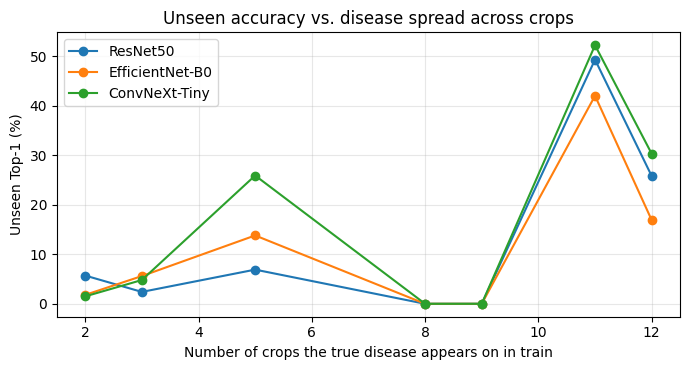

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for m in MODELS:
    t = out[m]["by_ncrops"]; ax.plot(t.index, t["top1"], marker="o", label=m)
ax.set_xlabel("Number of crops the true disease appears on in train")
ax.set_ylabel("Unseen Top-1 (%)"); ax.set_title("Unseen accuracy vs. disease spread across crops")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout()
plt.savefig(f"{RUN}/unseen_acc_vs_n_train_crops.png", dpi=150); plt.show()

## 7. Checksums, zip, and the team message

In [12]:
rows = []
for m in MODELS:
    f = f"{RUN}/{m}_best.pt"
    h = hashlib.sha256(open(f, "rb").read()).hexdigest()
    rows.append({"file": os.path.basename(f), "size_MB": round(os.path.getsize(f)/1e6, 1), "sha256": h})
ck = pd.DataFrame(rows); display(ck)
ck.to_csv(f"{RUN}/checkpoints_sha256.csv", index=False)
print(open(f"{RUN}/checkpoints_sha256.csv").read())

,file,size_MB,sha256
0,ResNet50_best.pt,95.8,78521ad49b18d945314aeeac73e41a2490fa387af13286...
1,EfficientNet-B0_best.pt,17.2,fd1b94ae723bd5816687ca13fe4b27165fac976f6d82df...
2,ConvNeXt-Tiny_best.pt,111.9,c18c6bbd8cb46afc4d78d5b3ad4a949024c21c808b92f4...


file,size_MB,sha256
ResNet50_best.pt,95.8,78521ad49b18d945314aeeac73e41a2490fa387af13286d7d9c79608fa9475e9
EfficientNet-B0_best.pt,17.2,fd1b94ae723bd5816687ca13fe4b27165fac976f6d82df93fe892d641f4e33f9
ConvNeXt-Tiny_best.pt,111.9,c18c6bbd8cb46afc4d78d5b3ad4a949024c21c808b92f4775b6898b8dd63d808



In [13]:
b = res[best]
print(f"""[v2 disease_independent] DONE
What: independent disease CNN, 3 backbones, shared v2 protocol
Best (Top-1): {best} - seen {b['seen']['1']:.1f} / unseen {b['unseen']['1']:.1f} / H {b['harmonic']['1']:.1f}
Pushed: disease_inde_cnn/output/disease_independent_v2/ (commit <hash>)
Checkpoints: {", ".join(m + "_best.pt" for m in MODELS)} (sent below; SHA-256 in README)
Notes: <anything off-protocol, problems, or "none">""")

[v2 disease_independent] DONE
What: independent disease CNN, 3 backbones, shared v2 protocol
Best (Top-1): ConvNeXt-Tiny - seen 64.3 / unseen 14.1 / H 23.1
Pushed: disease_inde_cnn/output/disease_independent_v2/ (commit <hash>)
Checkpoints: ResNet50_best.pt, EfficientNet-B0_best.pt, ConvNeXt-Tiny_best.pt (sent below; SHA-256 in README)
Notes: <anything off-protocol, problems, or "none">


In [14]:
# the zip includes the .pt checkpoints (for download); for git, copy the folder WITHOUT *.pt
os.chdir(OUT_ROOT)
!zip -rq disease_independent_v2.zip disease_independent_v2
print(os.path.getsize(f"{OUT_ROOT}/disease_independent_v2.zip") / 1e6, "MB")

210.208353 MB


### Checklist before pushing
- First log line shows split sizes 6995 / 773 / 227 / 2000 / 1448.
- `config.json` shows `"dataset": "DPD_Small_clean_v2"`, the pinned `timm_id`s and a GPU name.
- Section 4 reports **no missing files**; `summary.csv` has 3 rows.
- Save this notebook **with outputs** as `disease_independent_cnns_v2.ipynb` in `disease_inde_cnn/`.
- Copy the results folder (without `*.pt`) to `disease_inde_cnn/output/disease_independent_v2/`, fill in `README.md` from `README_TEMPLATE.md`, push, then post the message above and send the `.pt` files to the WhatsApp group **as documents**.
- Do not edit or delete the v1 folder.

### Notes for the report
- Compare `Seen(excl heldout)` with v1 seen, not `Seen`.
- Section 6 gives the evidence for the crop shortcut: unseen accuracy by number of training crops of the disease, and the share of wrong predictions that are a disease already seen on the true crop.
- Optional separate runs (Mixup/CutMix + EMA, class weights *or* a balanced sampler, crop-shortcut ideas) go in their own folders with copies of `train_independent.py`, tuned on `val` / `val_unseen` only.